# Data Pre-Processing




google colab link:

https://colab.research.google.com/drive/1b4jnA4D2ATWVkedW2jG2yejbAIVna8MI?usp=sharing

In [ ]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, roc_curve
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LogisticRegression

In [ ]:
# import and review dataset
df = pd.read_csv('churn-bigml-80.csv')
df.head()

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [ ]:
# check dataset information and missing value
df.info()
df.isna().any()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2666 entries, 0 to 2665
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   2666 non-null   object 
 1   Account length          2666 non-null   int64  
 2   Area code               2666 non-null   int64  
 3   International plan      2666 non-null   object 
 4   Voice mail plan         2666 non-null   object 
 5   Number vmail messages   2666 non-null   int64  
 6   Total day minutes       2666 non-null   float64
 7   Total day calls         2666 non-null   int64  
 8   Total day charge        2666 non-null   float64
 9   Total eve minutes       2666 non-null   float64
 10  Total eve calls         2666 non-null   int64  
 11  Total eve charge        2666 non-null   float64
 12  Total night minutes     2666 non-null   float64
 13  Total night calls       2666 non-null   int64  
 14  Total night charge      2666 non-null   

,0
State,False
Account length,False
Area code,False
International plan,False
Voice mail plan,False
Number vmail messages,False
Total day minutes,False
Total day calls,False
Total day charge,False
Total eve minutes,False


This dataset has 2666 rows and 20 columns with no missing values.

In [ ]:
# check 'International plan' and 'Voice mail plan' columns

df_interplan = df.groupby('International plan').size()
df_vicmlplan = df.groupby('Voice mail plan').size()
print(df_interplan)
print(df_vicmlplan)

International plan
No     2396
Yes     270
dtype: int64
Voice mail plan
No     1933
Yes     733
dtype: int64


In [ ]:
# prepare dataset

# converting 'Churn' column from boolean to integer(0 for False, 1 for True)
df['Churn'] = df['Churn'].astype(int)

# converting 'International plan' and 'Voice mail plan' columns from boolean to integer(0 for False, 1 for True)
df['International plan'] = df['International plan'].map({'Yes': 1, 'No': 0})
df['Voice mail plan'] = df['Voice mail plan'].map({'Yes': 1, 'No': 0})

# display the first few rows
df.head()

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,0,1,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,0
1,OH,107,415,0,1,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,0
2,NJ,137,415,0,0,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,0
3,OH,84,408,1,0,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,0
4,OK,75,415,1,0,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,0


In [ ]:
# exploratory data analysis

df['Churn'].value_counts(normalize=True)

,proportion
Churn,
0,0.854464
1,0.145536


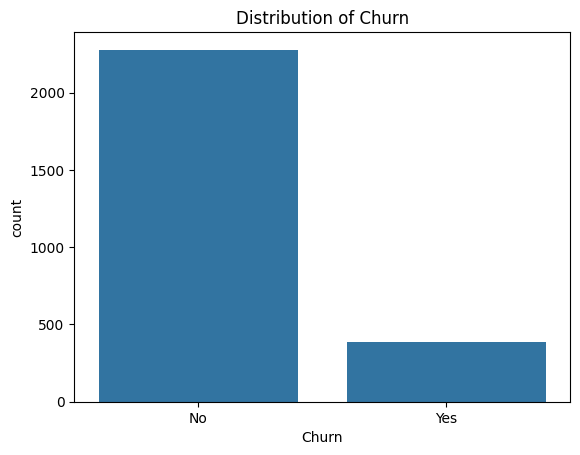

In [ ]:
# Exploratory Data Analysis: Focus on understanding patterns, distributions, and relationships

# Displaying the proportions of churn
df['Churn'].value_counts(normalize=True)

# Plotting the distribution of churn with a custom color palette
sns.countplot(x='Churn', data=df)
plt.xticks([0, 1], ['No', 'Yes'])
plt.title('Distribution of Churn')
plt.show()

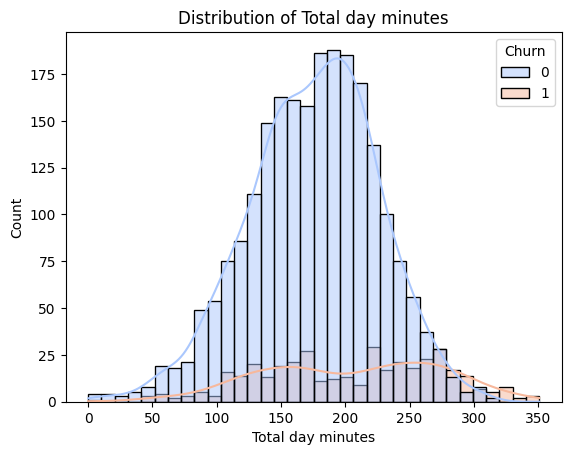

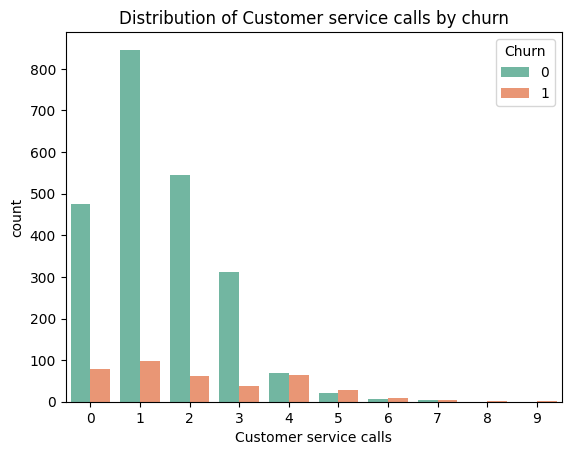

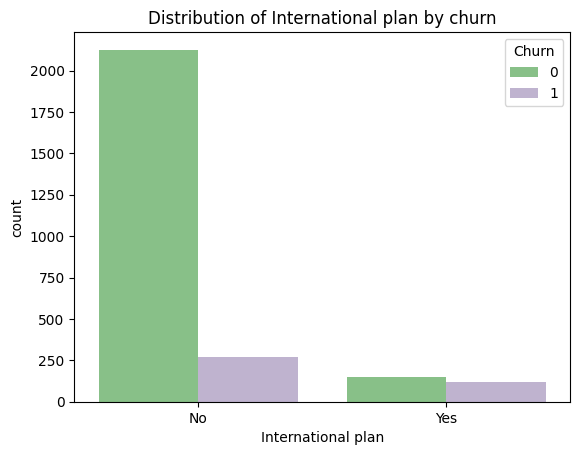

In [ ]:
# Distribution of 'Total day minutes' by churn
sns.histplot(x='Total day minutes', hue='Churn', data=df, kde=True, palette='coolwarm')
plt.title('Distribution of Total day minutes')
plt.show()

# Distribution of 'Customer service calls' by churn
sns.countplot(x='Customer service calls', hue='Churn', data=df, palette='Set2')
plt.title('Distribution of Customer service calls by churn')
plt.show()

# Distribution of 'International plan' by churn
sns.countplot(x='International plan', hue='Churn', data=df, palette='Accent')
plt.title('Distribution of International plan by churn')
plt.xticks([0, 1], ['No', 'Yes'])
plt.show()

Insights:

Total Day Minutes: Customers with higher day minutes tend to churn more frequently, indicating that heavy daytime usage may be a factor in churn.

Customer Service Calls: Customers with a lower number of service calls have a higher churn rate. As the number of customer service calls increases, the churn rate seems to decrease. This suggests that frequent interactions with customer service may actually help retain customers, potentially by addressing their concerns more effectively and enhancing customer satisfaction.

International Plan: Customers without an international plan are more likely to churn, which may highlight specific service expectations or costs associated with these plans.

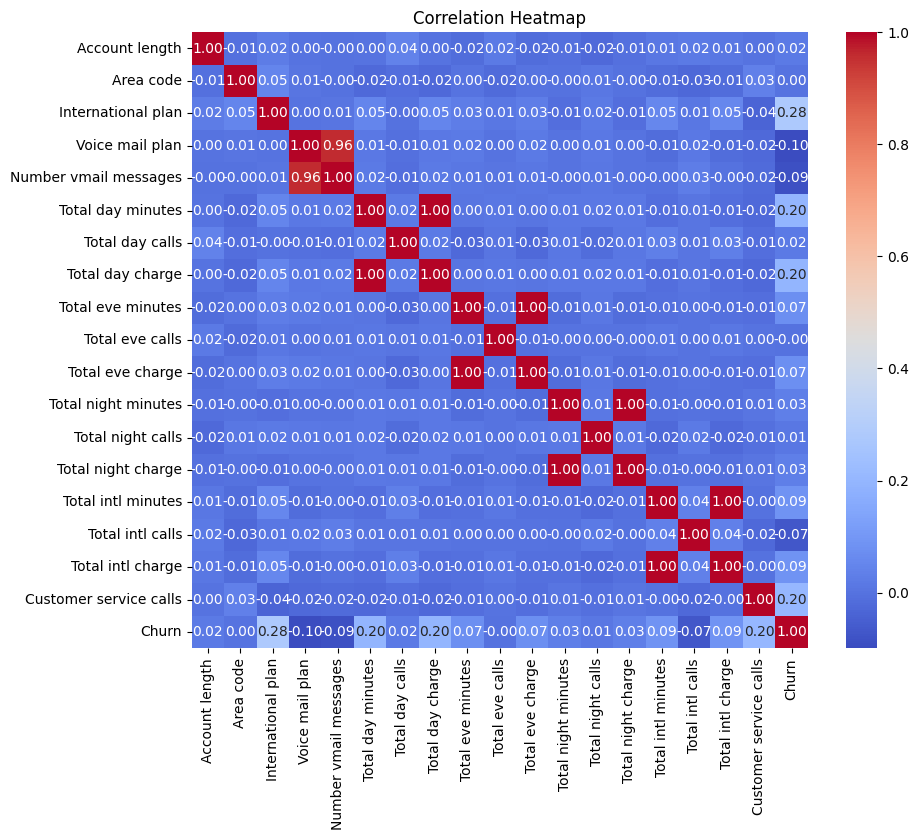

In [ ]:
# Check correlations between numerical features and churn
df_num = df.select_dtypes(include=['float64', 'int64'])

# Plot correlation heatmap with improved aesthetics
plt.figure(figsize=(10, 8))
sns.heatmap(df_num.corr(), annot=True, fmt=".2f", cmap="coolwarm", cbar=True, square=True)
plt.title('Correlation Heatmap')
plt.show()

Insights:

Strong correlations along the diagonal and among related features, such as Total day minutes and Total day charge.

In [ ]:
# Correlations
df_num.corr()['Churn'].sort_values(ascending=False)

,Churn
Churn,1.000000
International plan,0.277489
Customer service calls,0.202590
Total day charge,0.195689
Total day minutes,0.195688
Total intl charge,0.086216
Total intl minutes,0.086204
Total eve minutes,0.072906
Total eve charge,0.072893
Total night minutes,0.033639


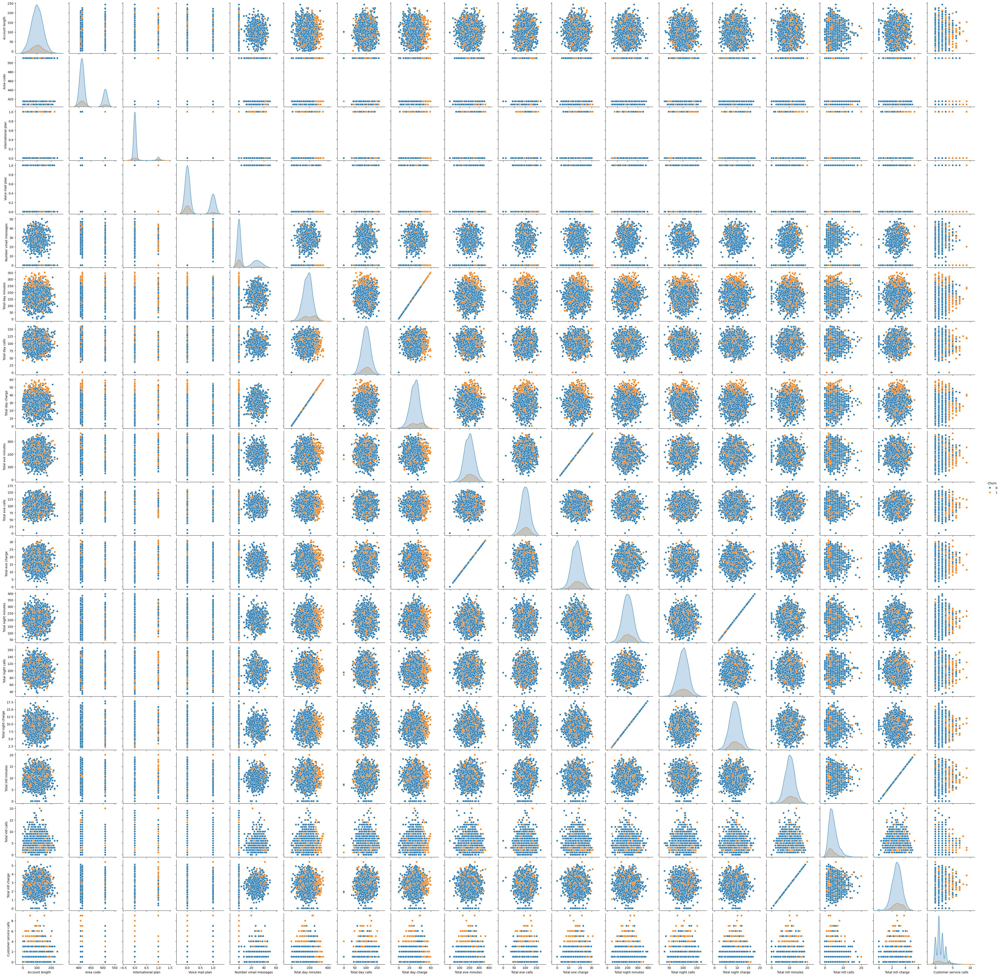

In [ ]:
sns.pairplot(df, hue='Churn')
plt.show()

Several of the numerical data are related to each other, such as: (Total day minutes and Total day charge), (Total eve minutes and Total eve charge), (Total night minutes and Total night charge) and (Total intl minutes and Total intl charge) are alo correlated. We only have to select one of them.

In [ ]:
# Remove unnecessary columns
df = df.drop(columns=['State', 'Area code', 'Total day charge', 'Total eve charge',
               'Total night charge', 'Total intl charge'])

# Creating a new column combines all minutes(day, eve, night, intl)
df['Total minutes'] = df['Total day minutes'] + df['Total eve minutes'] + df['Total night minutes'] + df['Total intl minutes']

In [ ]:
# Check dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2666 entries, 0 to 2665
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Account length          2666 non-null   int64  
 1   International plan      2666 non-null   int64  
 2   Voice mail plan         2666 non-null   int64  
 3   Number vmail messages   2666 non-null   int64  
 4   Total day minutes       2666 non-null   float64
 5   Total day calls         2666 non-null   int64  
 6   Total eve minutes       2666 non-null   float64
 7   Total eve calls         2666 non-null   int64  
 8   Total night minutes     2666 non-null   float64
 9   Total night calls       2666 non-null   int64  
 10  Total intl minutes      2666 non-null   float64
 11  Total intl calls        2666 non-null   int64  
 12  Customer service calls  2666 non-null   int64  
 13  Churn                   2666 non-null   int64  
 14  Total minutes           2666 non-null   

In [ ]:
# Data splitting

# define features(x) and target(y)
X = df.drop(columns=['Churn'])
y = df['Churn']

# split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# feature scaling
# initialize the scaler and fit it to the training date
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# print the shapes of the resulting sets
print(X_train_scaled.shape)
print(X_test_scaled.shape)
print(y_train.shape)
print(y_test.shape)

(2132, 14)
(534, 14)
(2132,)
(534,)


# Model Build

## Decision Tree Method

In [ ]:
# Initialize Decision Tree model
decision_tree = DecisionTreeClassifier(random_state=42)

# Dictionary to store evaluation results
results = {}

# Train the model
print("Evaluating Model: Decision Tree")
decision_tree.fit(X_train_scaled, y_train)

# Predict on the test set
y_pred = decision_tree.predict(X_test_scaled)
y_pred_proba = decision_tree.predict_proba(X_test_scaled)[:, 1]

# Classification Metrics
report = classification_report(y_test, y_pred)
auc_score = roc_auc_score(y_test, y_pred_proba)
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

# Regression Metrics (Using probabilities for calculation)
absolute_errors = np.abs(y_test - y_pred_proba)
mae = mean_absolute_error(y_test, y_pred_proba)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_proba))

# Store results
results["Decision Tree"] = {
    "Classification Report": report,
    "AUC Score": auc_score,
    "FPR": fpr,
    "TPR": tpr,
    "MAE": mae,
    "AE": absolute_errors.tolist(),  # Store as list for readability
    "RMSE": rmse
}

# Print classification report, AUC score, and regression metrics
print("\nClassification Report for Decision Tree:\n")
print(report)
print(f"AUC-ROC Score: {auc_score:.2f}")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}\n")
print("-" * 50)


Evaluating Model: Decision Tree

Classification Report for Decision Tree:

              precision    recall  f1-score   support

           0       0.95      0.95      0.95       455
           1       0.72      0.73      0.72        79

    accuracy                           0.92       534
   macro avg       0.83      0.84      0.84       534
weighted avg       0.92      0.92      0.92       534

AUC-ROC Score: 0.84
Mean Absolute Error (MAE): 0.08
Root Mean Squared Error (RMSE): 0.29

--------------------------------------------------


Analysis of Decision Tree Results:

Classification Performance:

Class 0: Excellent precision (0.95), recall (0.95), and F1-score (0.95), indicating strong performance on the majority class.

Class 1: Lower precision (0.72) and recall (0.73), likely due to class imbalance (455 vs. 79 samples).

Overall Accuracy: High at 92%, with a weighted F1-score of 0.92.
AUC-ROC Score:

AUC: 0.84, indicating good ability to distinguish between classes, though there’s room for improvement.

Error Metrics:
MAE: 0.08, and RMSE: 0.29, showing low overall error in predicted probabilities.

Summary:
The model performs well for the majority class but struggles with the minority class due to imbalance.

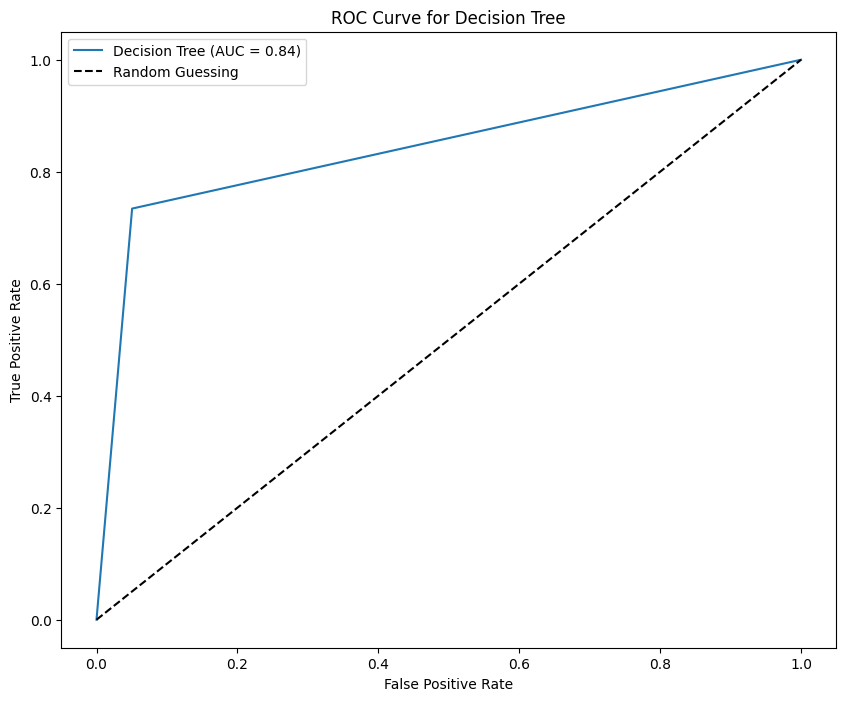

In [ ]:
# Plot ROC Curve for Decision Tree
plt.figure(figsize=(10, 8))

# Extract results for Decision Tree
decision_tree_result = results["Decision Tree"]

# Plot ROC Curve
plt.plot(decision_tree_result["FPR"], decision_tree_result["TPR"],
         label=f"Decision Tree (AUC = {decision_tree_result['AUC Score']:.2f})")
plt.plot([0, 1], [0, 1], 'k--', label="Random Guessing")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for Decision Tree")
plt.legend(loc="best")
plt.show()


AUC Score:
0.84, indicating good model performance and strong class separation, far better than random guessing (AUC = 0.5).

Curve Shape: High true positive rate at low false positive rates, though performance flattens as the false positive rate increases.

Summary: The Decision Tree model performs well overall, with balanced classification capability, but could still be optimized for critical scenarios.

## Logistic regression Method

In [ ]:
# Initialize Logistic Regression model
logistic_regression = LogisticRegression(random_state=42)

# Dictionary to store evaluation results
results = {}

# Train the model
print("Evaluating Model: Logistic Regression")
logistic_regression.fit(X_train_scaled, y_train)

# Predict on the test set
y_pred = logistic_regression.predict(X_test_scaled)
y_pred_proba = logistic_regression.predict_proba(X_test_scaled)[:, 1]

# Classification Metrics
report = classification_report(y_test, y_pred)
auc_score = roc_auc_score(y_test, y_pred_proba)
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

# Regression Metrics (Using probabilities for calculation)
absolute_errors = np.abs(y_test - y_pred_proba)
mae = mean_absolute_error(y_test, y_pred_proba)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_proba))

# Store results
results["Logistic Regression"] = {
    "Classification Report": report,
    "AUC Score": auc_score,
    "FPR": fpr,
    "TPR": tpr,
    "MAE": mae,
    "AE": absolute_errors.tolist(),  # Store as list for readability
    "RMSE": rmse
}

# Print classification report, AUC score, and regression metrics
print("\nClassification Report for Logistic Regression:\n")
print(report)
print(f"AUC-ROC Score: {auc_score:.2f}")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}\n")
print("-" * 50)


Evaluating Model: Logistic Regression

Classification Report for Logistic Regression:

              precision    recall  f1-score   support

           0       0.88      0.97      0.92       455
           1       0.58      0.23      0.33        79

    accuracy                           0.86       534
   macro avg       0.73      0.60      0.63       534
weighted avg       0.83      0.86      0.83       534

AUC-ROC Score: 0.78
Mean Absolute Error (MAE): 0.20
Root Mean Squared Error (RMSE): 0.33

--------------------------------------------------



Logistic Regression Analysis:

Class 0: Excellent performance with high precision (0.88), recall (0.97), and F1-score (0.92).

Class 1: Poor recall (0.23) and F1-score (0.33), struggling with the minority class.

Overall: Accuracy (86%) and AUC (0.78) show decent performance but favor the majority class.

Errors: Moderate MAE (0.20) and RMSE (0.33).


Summary: Strong for the majority class but weak for the minority class.

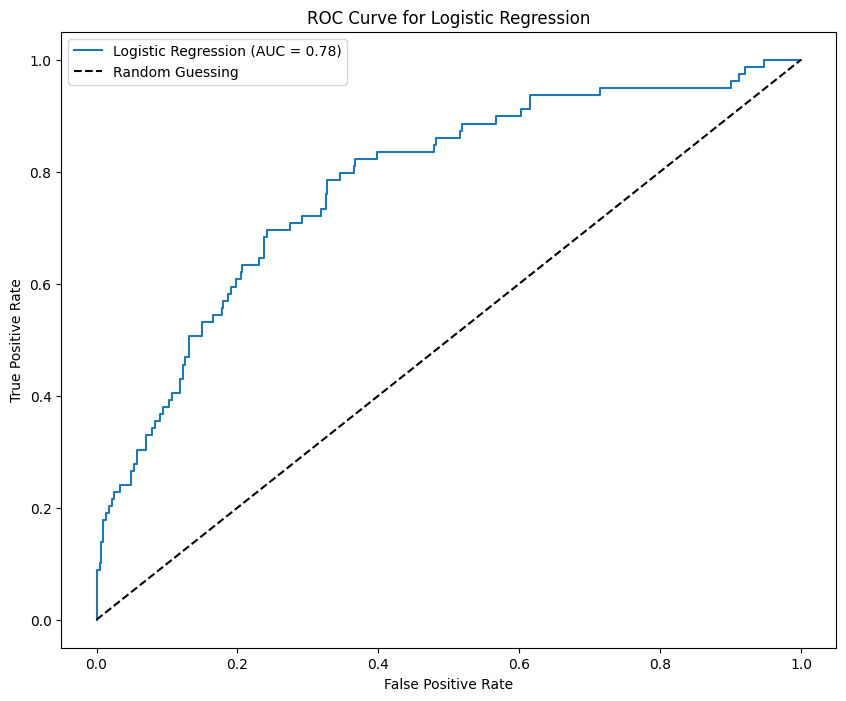

In [ ]:
# Plot ROC Curve for Logistic Regression
plt.figure(figsize=(10, 8))

# Extract results for Logistic Regression
logistic_regression_result = results["Logistic Regression"]

# Plot ROC Curve
plt.plot(logistic_regression_result["FPR"], logistic_regression_result["TPR"],
         label=f"Logistic Regression (AUC = {logistic_regression_result['AUC Score']:.2f})")
plt.plot([0, 1], [0, 1], 'k--', label="Random Guessing")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for Logistic Regression")
plt.legend(loc="best")
plt.show()



ROC Curve Analysis:

AUC = 0.78: Shows moderate discrimination, better than random guessing.

Curve: Predictive power is present but lacks a sharp rise near the top-left corner.

Summary: Decent performance, but struggles with class balance

## Random Forest Method

In [ ]:
# Initialize Random Forest model
random_forest = RandomForestClassifier(random_state=42, n_estimators=100)

# Dictionary to store evaluation results
results = {}

# Train the model
print("Evaluating Model: Random Forest")
random_forest.fit(X_train_scaled, y_train)

# Predict on the test set
y_pred = random_forest.predict(X_test_scaled)
y_pred_proba = random_forest.predict_proba(X_test_scaled)[:, 1]

# Classification Metrics
report = classification_report(y_test, y_pred)
auc_score = roc_auc_score(y_test, y_pred_proba)
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

# Regression Metrics (Using probabilities for calculation)
absolute_errors = np.abs(y_test - y_pred_proba)
mae = mean_absolute_error(y_test, y_pred_proba)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_proba))

# Store results
results["Random Forest"] = {
    "Classification Report": report,
    "AUC Score": auc_score,
    "FPR": fpr,
    "TPR": tpr,
    "MAE": mae,
    "AE": absolute_errors.tolist(),  # Store as list for readability
    "RMSE": rmse
}

# Print classification report, AUC score, and regression metrics
print("\nClassification Report for Random Forest:\n")
print(report)
print(f"AUC-ROC Score: {auc_score:.2f}")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}\n")
print("-" * 50)


Evaluating Model: Random Forest

Classification Report for Random Forest:

              precision    recall  f1-score   support

           0       0.95      1.00      0.98       455
           1       1.00      0.72      0.84        79

    accuracy                           0.96       534
   macro avg       0.98      0.86      0.91       534
weighted avg       0.96      0.96      0.96       534

AUC-ROC Score: 0.90
Mean Absolute Error (MAE): 0.12
Root Mean Squared Error (RMSE): 0.21

--------------------------------------------------


Random Forest Results Analysis:

Classification Metrics:

Class 0: Outstanding performance with precision (0.95), recall (1.00), and F1-score (0.98).
Class 1: High precision (1.00) but lower recall (0.72), resulting in an F1-score of 0.84.

Overall Performance:

Accuracy: 96%, reflecting strong model performance overall.
Macro Avg: F1-score of 0.91, showing balanced performance across classes.
Weighted Avg: Matches the high overall accuracy and performance.
AUC-ROC Score:
AUC = 0.90: Excellent ability to separate classes.

Error Metrics:

MAE: 0.12, and RMSE: 0.21, both indicating low prediction error.

Summary:
The Random Forest model performs exceptionally well, especially for the majority class, with robust overall metrics. Slight improvement in recall for the minority class could further enhance results.

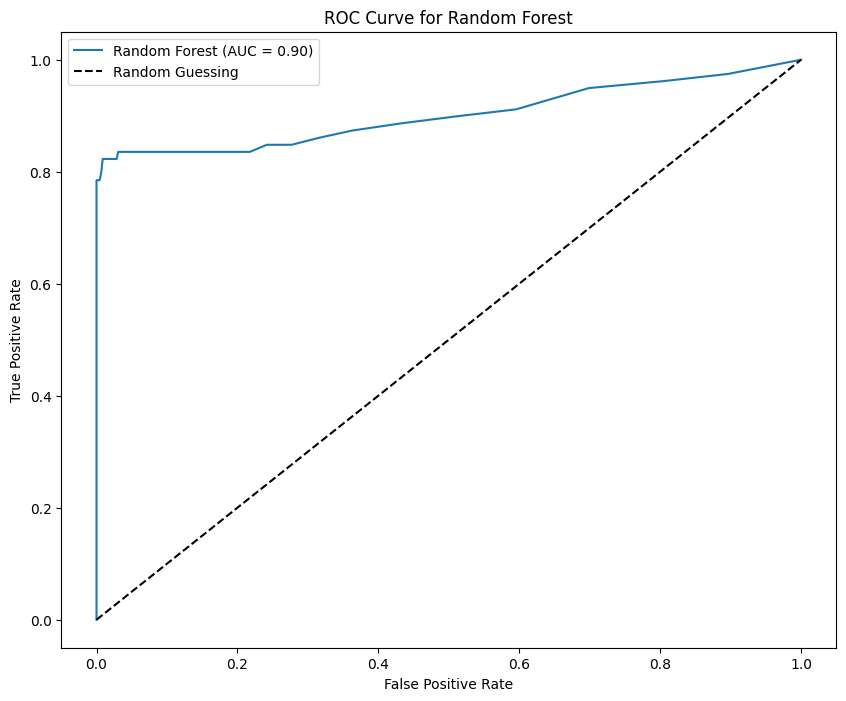

In [ ]:
# Plot ROC Curve for Random Forest
plt.figure(figsize=(10, 8))

# Extract results for Random Forest
random_forest_result = results["Random Forest"]

# Plot ROC Curve
plt.plot(random_forest_result["FPR"], random_forest_result["TPR"],
         label=f"Random Forest (AUC = {random_forest_result['AUC Score']:.2f})")
plt.plot([0, 1], [0, 1], 'k--', label="Random Guessing")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for Random Forest")
plt.legend(loc="best")
plt.show()


ROC Curve Analysis:

AUC = 0.90: Excellent class separation.

Curve: Steep rise indicates strong predictive performance with low false positives.

Summary: Reliable and highly effective model for classification.

# Evaluation Part and Model Choose

Model Selection:

Recommendation: Random Forest


Reasons:

Overall Performance: Random Forest has the highest accuracy (96%) and AUC-ROC score (0.90), indicating strong class separation and reliable predictions.

Balanced Metrics: It performs well on both majority and minority classes, with precision, recall, and F1-scores being consistently high.

Error Metrics: Lowest MAE (0.12) and RMSE (0.21), showing minimal prediction error.


Comparison:

Decision Tree: Decent performance but slightly lower AUC (0.84) and higher errors (MAE = 0.08, RMSE = 0.29).

Logistic Regression: Struggles with the minority class (low recall and F1-score) and has the lowest AUC (0.78).

Random Forest offers the best trade-off between accuracy, class balance, and error rates, making it the most suitable choice.






